# Fuerza de Marea

In [1]:
import rebound
import reboundx
import numpy as np 
import matplotlib.pyplot as plt

In [2]:
sim = rebound.Simulation()
sim.integrator = "ias15"
sim.units = ("AU", "yr", "Msun")

In [3]:
sim.add(m=1, r=0.00465047)
sim.add(m=1e-3, a=0.05, e=0.8, r=0.0000477895)
sim.move_to_com()

In [4]:
c_au_yr = 63239.7263
rebx = reboundx.Extras(sim)
gr = rebx.load_force("gr")
rebx.add_force(gr)
gr.params["c"] = c_au_yr

In [5]:
sim.integrate(0.0)
sim.widget(size=(950,950))

REBOUND Webserver listening on http://localhost:1234 (not secure) ...


In [6]:
a1 = []
e1 = []
t1 = []
H0 = rebx.gr_hamiltonian(gr)
pomega1 = []
err_H = []

tmax = 1000
Num = 100
times = np.linspace(0, tmax, Num)

for i, time in enumerate(times):
    sim.integrate(time)
    t1.append(times[i])
    a1.append(sim.particles[1].a)
    e1.append(sim.particles[1].e)
    pomega1.append(sim.particles[1].pomega)
    Hf = rebx.gr_hamiltonian(gr)
    err_H.append(abs(Hf - H0)/abs(H0))

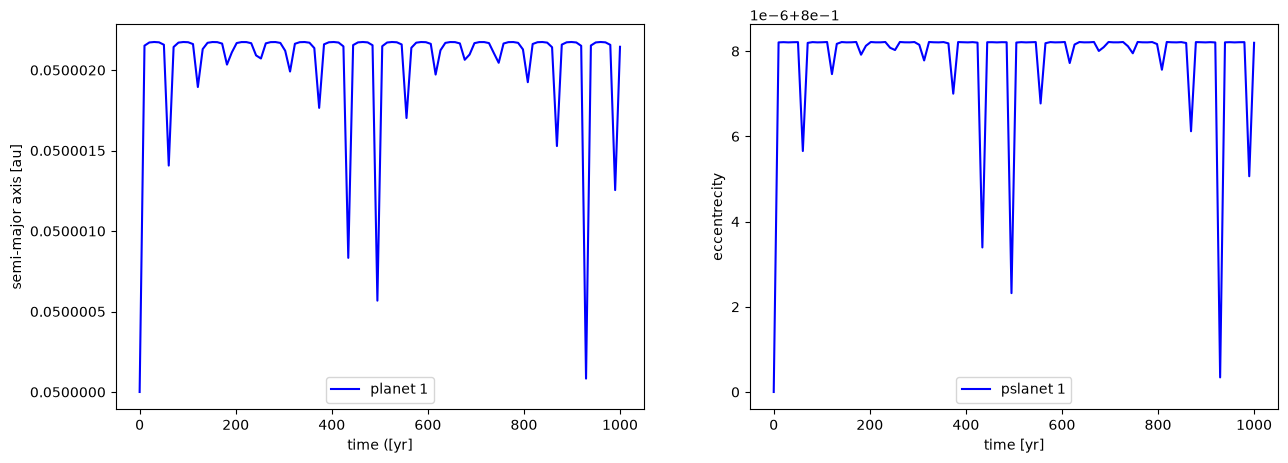

In [7]:
fig = plt.figure(figsize=(15,5))

ax = plt.subplot(121)
ax.set_xlabel("time ([yr]")
ax.set_ylabel("semi-major axis [au]")
# ax.set_ylabel("err_ener")
plt.plot(t1, a1, color="blue", label="planet 1")
# plt.plot(t1, err_ener, color="blue", label="planet 1")
ax.legend(loc="best")

ax = plt.subplot(122)
ax.set_xlabel("time [yr]")
ax.set_ylabel("eccentrecity")
# ax.set_ylabel("err_ang")
plt.plot(t1, e1, color="blue", label="pslanet 1")
# plt.plot(t1, err_ang, color="blue", label="planet 1")
ax.legend(loc="best")

/tmp/ipykernel_26592/441935216.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc="best")
/tmp/ipykernel_26592/441935216.py:13: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc="best")


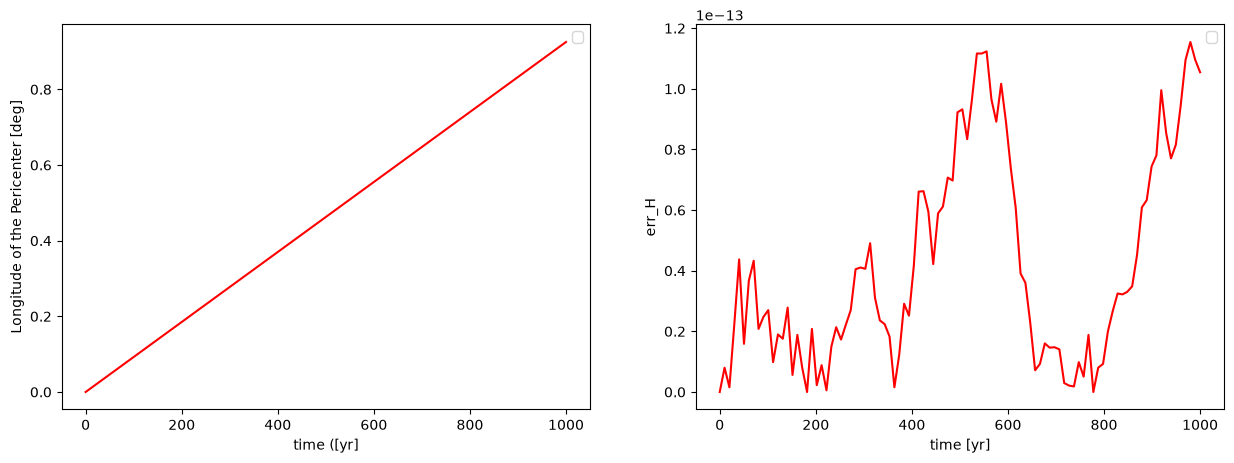

In [8]:
fig = plt.figure(figsize=(15,5))

ax = plt.subplot(121)
ax.set_xlabel("time ([yr]")
ax.set_ylabel("Longitude of the Pericenter [deg]")
plt.plot(t1, pomega1, color="red")
ax.legend(loc="best")

ax = plt.subplot(122)
ax.set_xlabel("time [yr]")
ax.set_ylabel("err_H")
plt.plot(t1, err_H, color="red")
ax.legend(loc="best")